In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

import pickle

import xgboost as xgb
print(xgb.__version__)

3.2.0


In [2]:
train = pd.read_csv('../Data/train_imputed.csv')
oot1 = pd.read_csv('../Data/oot1_imputed.csv')
oot2 = pd.read_csv('../Data/oot2_imputed.csv')

feats_to_drop = pickle.load(open('../Files/selected_features.csv', 'rb'))['final_features_to_drop']

id_vars = ['id', 'data_type', 'HQ_city', 'ateco_sector']
target_var = 'default'
feature_vars = [col for col in train.columns if col not in id_vars + [target_var] + feats_to_drop]
categorical_features = ['legal_structure_category', 'sector_category']

train[categorical_features] = train[categorical_features].astype('string')
oot1[categorical_features] = oot1[categorical_features].astype('string')
oot2[categorical_features] = oot2[categorical_features].astype('string')
print(train.shape, oot1.shape, oot2.shape)

(475389, 30) (174229, 30) (183730, 30)


In [3]:
ID_train = train[id_vars + [target_var] + categorical_features]
X_train = train[feature_vars]
y_train = train[target_var]

ID_oot1 = oot1[id_vars + [target_var] + categorical_features]
X_oot1 = oot1[feature_vars]
y_oot1 = oot1[target_var]

ID_oot2 = oot2[id_vars + [target_var] + categorical_features]
X_oot2 = oot2[feature_vars]
y_oot2 = oot2[target_var]

In [4]:
category_types = {}

for col in categorical_features:
    dtype = pd.CategoricalDtype(
        categories=X_train[col].dropna().unique()
    )
    category_types[col] = dtype

    X_train[col] = X_train[col].astype(dtype)
    X_oot1[col] = X_oot1[col].astype(dtype)
    X_oot2[col] = X_oot2[col].astype(dtype)

/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_90725/217081448.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train[col] = X_train[col].astype(dtype)
/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_90725/217081448.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_oot1[col] = X_oot1[col].astype(dtype)
/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_90725/217081448.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
T

In [5]:
xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    use_label_encoder=False,
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    enable_categorical=True,
    early_stopping_rounds=50
)

In [6]:
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_oot1, y_oot1)],
    verbose=50
)

[0]	validation_0-auc:0.78115	validation_1-auc:0.76087


/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/xgboost/callback.py:385: UserWarning: [20:06:41] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  self.starting_round = model.num_boosted_rounds()


[50]	validation_0-auc:0.85138	validation_1-auc:0.81793
[100]	validation_0-auc:0.86490	validation_1-auc:0.82258
[150]	validation_0-auc:0.87401	validation_1-auc:0.82382
[200]	validation_0-auc:0.88139	validation_1-auc:0.82416
[232]	validation_0-auc:0.88554	validation_1-auc:0.82438


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,50
,enable_categorical,True
,eval_metric,'auc'


In [7]:
pickle.dump(xgb_model, open('../Artifacts/xgb_model_ratio_and_flag_features_imputed.pkl', 'wb'))

In [8]:
train_pred = xgb_model.predict_proba(X_train)[:, 1]
oot1_pred = xgb_model.predict_proba(X_oot1)[:, 1]
oot2_pred = xgb_model.predict_proba(X_oot2)[:, 1]

In [9]:
scores_train = pd.concat([ID_train, pd.DataFrame({'y_true': y_train, 'y_pred': train_pred})], axis=1)
scores_oot1 = pd.concat([ID_oot1, pd.DataFrame({'y_true': y_oot1, 'y_pred': oot1_pred})], axis=1)
scores_oot2 = pd.concat([ID_oot2, pd.DataFrame({'y_true': y_oot2, 'y_pred': oot2_pred})], axis=1)

In [10]:
scores_train.to_csv('../Model_scores/scores_train_imputed.csv', index=False)
scores_oot1.to_csv('../Model_scores/scores_oot1_imputed.csv', index=False)
scores_oot2.to_csv('../Model_scores/scores_oot2_imputed.csv', index=False)

# features[id_vars + categorical_features].to_csv('../Model_scores/categorical_features.csv', index=False)

In [11]:
roc_auc_train = roc_auc_score(scores_train['y_true'], scores_train['y_pred'])
roc_auc_oot1 = roc_auc_score(scores_oot1['y_true'], scores_oot1['y_pred'])
roc_auc_oot2 = roc_auc_score(scores_oot2['y_true'], scores_oot2['y_pred'])

print(f"Train ROC AUC: {roc_auc_train:.4f}")
print(f"oot1 ROC AUC: {roc_auc_oot1:.4f}")
print(f"OOT2 ROC AUC: {roc_auc_oot2:.4f}")

Train ROC AUC: 0.8787
oot1 ROC AUC: 0.8245
OOT2 ROC AUC: 0.8411


In [12]:
fpr_train, tpr_train, thresholds_train = roc_curve(scores_train['y_true'], scores_train['y_pred'])
fpr_oot1, tpr_oot1, thresholds_oot1 = roc_curve(scores_oot1['y_true'], scores_oot1['y_pred'])
fpr_oot2, tpr_oot2, thresholds_oot2 = roc_curve(scores_oot2['y_true'], scores_oot2['y_pred'])

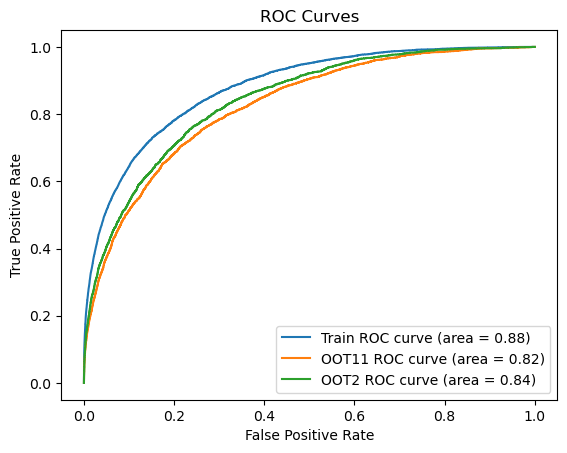

In [13]:
plt.plot(fpr_train, tpr_train, label='Train ROC curve (area = %0.2f)' % roc_auc_score(scores_train['y_true'], scores_train['y_pred']))
plt.plot(fpr_oot1, tpr_oot1, label='OOT11 ROC curve (area = %0.2f)' % roc_auc_score(scores_oot1['y_true'], scores_oot1['y_pred']))
plt.plot(fpr_oot2, tpr_oot2, label='OOT2 ROC curve (area = %0.2f)' % roc_auc_score(scores_oot2['y_true'], scores_oot2['y_pred']))
plt.legend()
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.show()

In [15]:
feature_importance_df = pd.DataFrame({
    'features': feature_vars,
    'importance': xgb_model.feature_importances_
}).sort_values(by='importance', ascending=False).reset_index(drop=True)

iv_df = pd.read_csv('../Files/iv_df.csv')[['features', 'iv_train']]
feature_importance_df = feature_importance_df.merge(iv_df, on='features', how='inner')
feature_importance_df['importance'] = feature_importance_df['importance'].apply(lambda x: f"{x:.2%}")
feature_importance_df['iv_train'] = feature_importance_df['iv_train'].apply(lambda x: f"{x:.4f}")
feature_importance_df.to_csv('../Artifacts/feature_importance_df_ratio_and_flag_features_imputed.csv', index=False)
feature_importance_df

,features,importance,iv_train
0,net_profit_assets,25.40%,0.7780
1,operating_cashflow_assets,17.09%,0.7747
2,equity_assets,11.14%,0.6212
3,short_term_debt_assets,8.08%,0.4948
4,cashflow_liabilities_proxy,6.16%,0.8209
5,roe,3.75%,0.7876
6,receivables_assets,3.67%,0.1371
7,sector_category,3.63%,0.0314
8,operating_profit_assets,3.46%,0.6153
9,interest_coverage_proxy,3.09%,0.5556


100%|██████████| 100/100 [00:04<00:00, 20.31it/s]


Mean bootstrap AUC: 0.8411
95% confidence interval: [0.8328, 0.8491]


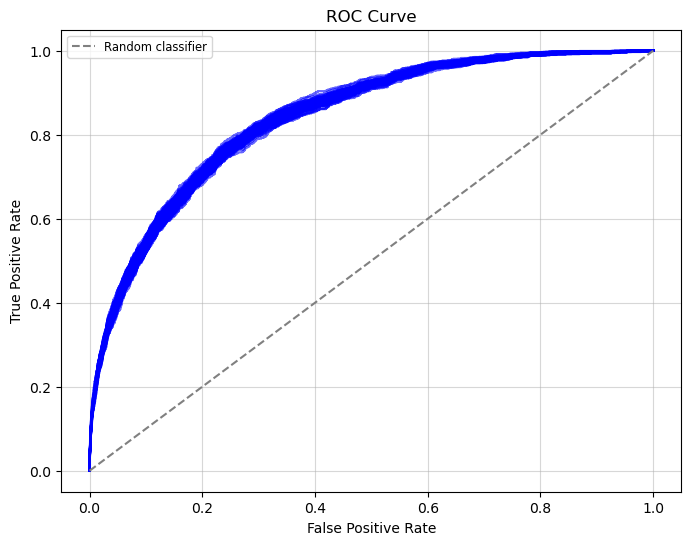

In [16]:
y = scores_oot2['y_true'].to_numpy()
score = scores_oot2['y_pred'].to_numpy()

n_bootstrap = 100
rng = np.random.default_rng(42)
aucs = []

plt.figure(figsize=(8, 6))

for i in tqdm(range(n_bootstrap)):
    indices = rng.choice(len(y), size=len(y), replace=True)
    y_bootstrap = y[indices]
    score_bootstrap = score[indices]

    roc_auc_bootstrap = roc_auc_score(y_bootstrap, score_bootstrap)
    aucs.append(roc_auc_bootstrap)
    fpr_bootstrap, tpr_bootstrap, _ = roc_curve(y_bootstrap, score_bootstrap)

    plt.plot(fpr_bootstrap, tpr_bootstrap, 'b', alpha=0.6)

auc_mean = np.mean(aucs)
auc_lower, auc_upper = np.percentile(aucs, [2.5, 97.5])
print(f"Mean bootstrap AUC: {auc_mean:.4f}")
print(f"95% confidence interval: [{auc_lower:.4f}, {auc_upper:.4f}]")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(fontsize="small")
plt.grid(alpha=0.5)
plt.show()